In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.stats import gaussian_kde


In [2]:
df = pd.read_csv('Unit06 iris.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [4]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


# Loading Dataset

In [5]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


# Select of the features

In [6]:
X = df.drop(columns=["species"])
y_real = df["species"]

# Scaling of the Features

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K means implementation

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_ = kmeans.fit_predict(X_scaled)

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^

# Cluster addition to the Df

In [9]:
df["cluster"] = cluster_

# Clusters contingency table

In [10]:
tab_comparison = pd.crosstab(
    df["species"],
    df["cluster"],
    rownames=["Species real"],
    colnames=["Cluster K-Means"],
)

In [11]:
print("--- (CROSS-TABULATION) ---")
print(tab_comparison)

--- (CROSS-TABULATION) ---
Cluster K-Means   0   1   2
Species real               
setosa            0  50   0
versicolor       39   0  11
virginica        14   0  36


# Setosa cluster is perfectly distict from the oteher while versicolor and virginica have some overlaping values

# ADJUSTED RAND INDEX (ARI) 

It helps in compare the different cluster with the real labels

In [12]:
from sklearn.metrics import adjusted_rand_score

In [13]:
ari_score = adjusted_rand_score(y_real, cluster_)

In [14]:
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}\n")

Adjusted Rand Index (ARI): 0.6201



To understand exactly what this number means, imagine the ARI as a scale ranging from 0 to 1:
* **1.0 (Perfection):** The clusters found are 100% identical to the true species.
* **0.6201 (Your Result):** There is a strong and significant similarity between the clusters and the species. The algorithm has captured the true structure of the data, making only minor, inevitable errors.
* **0.0 (Useless):** The algorithm assigned the flowers randomly, as if it had flipped a coin.

# Visualising K means

## Reduction with PCA

In [15]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [16]:
df_vis = pd.DataFrame(X_pca, columns=["Comp 1", "Comp 2"])

In [17]:
feature_names = X.columns

In [18]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["Comp 1", "Comp 2"],
    index=feature_names,
)

In [19]:
print("--- Matrix of weights (LOADINGS)  ---")
print(loadings.round(3))

--- Matrix of weights (LOADINGS)  ---
              Comp 1  Comp 2
sepal_length   0.522   0.372
sepal_width   -0.263   0.926
petal_length   0.581   0.021
petal_width    0.566   0.065


In [20]:
df_vis["Cluster"] = (
    cluster_.astype(str)
) 
df_vis["Real Species"] = y_real
df_vis

,Comp 1,Comp 2,Cluster,Real Species
0,-2.264542,0.505704,1,setosa
1,-2.086426,-0.655405,1,setosa
2,-2.367950,-0.318477,1,setosa
3,-2.304197,-0.575368,1,setosa
4,-2.388777,0.674767,1,setosa
...,...,...,...,...
145,1.870522,0.382822,2,virginica
146,1.558492,-0.905314,0,virginica
147,1.520845,0.266795,2,virginica
148,1.376391,1.016362,2,virginica


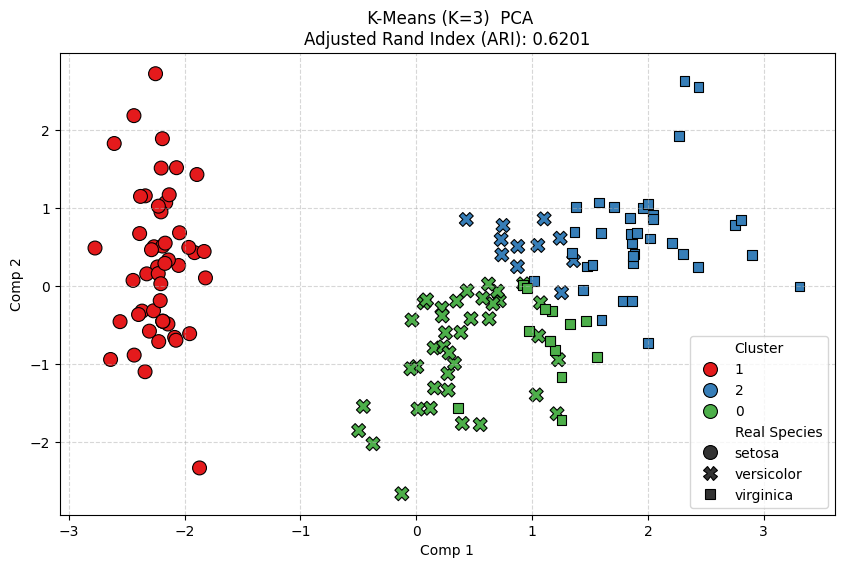

In [21]:
plt.figure(figsize=(10, 6))

# Usiamo lo stile dei punti (marker) per la Specie Reale e il Colore per il Cluster del K-Means
sns.scatterplot(
    data=df_vis,
    x="Comp 1",
    y="Comp 2",
    hue="Cluster",
    style="Real Species",
    palette="Set1",
    s=100,
    edgecolor="black",
)

plt.title(
    f" K-Means (K=3)  PCA\nAdjusted Rand Index (ARI): {ari_score:.4f}"
)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()